# 2D Heat Diffusion Lab
### An Interactive CUDA Programming Demonstration

**Course:** GPU Programming — IIT Jodhpur  
**Problem:** 2D Heat Diffusion with Convergence Detection

## Project Overview

This project simulates heat diffusion across a two-dimensional temperature grid using the five-point stencil method. The simulation updates interior grid cells iteratively while maintaining fixed boundary temperatures until the maximum temperature change falls below a specified tolerance.

## Explore the Lab

1. **Interactive Heatmap:** Explore the converged temperature distribution by changing the grid size and tolerance.
2. **Live Heat Diffusion:** Watch heat spread across the grid through an iteration-based animation.
3. **CUDA Performance Lab:** Compare previously measured execution times for global-memory and shared-memory implementations.

**Implementation note:** The interactive heatmap and animation use a Python CPU reference. The performance section displays measurements collected from the CUDA implementations.

In [9]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0


In [ ]:
%%writefile cuda_test.cu
#include <iostream>
#include <cuda_runtime.h>

__global__ void addVectors(int *a, int *b, int *c, int n) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;

    if (i < n) {
        c[i] = a[i] + b[i];
    }
}

int main() {
    const int N = 8;
    int a[N] = {1, 2, 3, 4, 5, 6, 7, 8};
    int b[N] = {10, 20, 30, 40, 50, 60, 70, 80};
    int c[N];

    int *d_a, *d_b, *d_c;

    cudaMalloc(&d_a, N * sizeof(int));
    cudaMalloc(&d_b, N * sizeof(int));
    cudaMalloc(&d_c, N * sizeof(int));

    cudaMemcpy(d_a, a, N * sizeof(int), cudaMemcpyHostToDevice);
    cudaMemcpy(d_b, b, N * sizeof(int), cudaMemcpyHostToDevice);

    addVectors<<<1, 256>>>(d_a, d_b, d_c, N);

    cudaError_t err = cudaGetLastError();
    if (err != cudaSuccess) {
        std::cerr << "Kernel launch failed: "
                  << cudaGetErrorString(err) << std::endl;
        return 1;
    }

    err = cudaDeviceSynchronize();
    if (err != cudaSuccess) {
        std::cerr << "GPU execution failed: "
                  << cudaGetErrorString(err) << std::endl;
        return 1;
    }

    cudaMemcpy(c, d_c, N * sizeof(int), cudaMemcpyDeviceToHost);

    std::cout << "CUDA vector addition results:\n";
    bool correct = true;

    for (int i = 0; i < N; i++) {
        std::cout << c[i] << " ";
        if (c[i] != a[i] + b[i]) correct = false;
    }

    std::cout << "\n";
    std::cout << (correct ? "TEST PASSED" : "TEST FAILED") << "\n";

    cudaFree(d_a);
    cudaFree(d_b);
    cudaFree(d_c);

    return correct ? 0 : 1;
}

Overwriting cuda_test.cu


In [ ]:
!nvcc cuda_test.cu -o cuda_test

In [ ]:
!./cuda_test

CUDA vector addition results:
11 22 33 44 55 66 77 88 
TEST PASSED


In [ ]:

%%writefile heat_diffusion.cu
#include <iostream>
#include <vector>
#include <cmath>
#include <chrono>
#include <cstring>
#include <fstream>
#include <cuda_runtime.h>

#define CUDA_CHECK(call) do { \
    cudaError_t err = (call); \
    if (err != cudaSuccess) { \
        std::cerr << "CUDA error: " \
                  << cudaGetErrorString(err) << std::endl; \
        return 1; \
    } \
} while (0)

__global__ void heatStep(
    const float* oldGrid,
    float* newGrid,
    int N,
    int* maxChangeBits)
{
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;

    if (x >= N || y >= N) return;

    int idx = y * N + x;

    // Keep boundary temperatures fixed.
    if (x == 0 || y == 0 || x == N - 1 || y == N - 1) {
        newGrid[idx] = oldGrid[idx];
        return;
    }

    float newTemp = (
        oldGrid[(y - 1) * N + x] +
        oldGrid[(y + 1) * N + x] +
        oldGrid[y * N + x - 1] +
        oldGrid[y * N + x + 1]
    ) / 4.0f;

    newGrid[idx] = newTemp;

    float change = fabsf(newTemp - oldGrid[idx]);
    atomicMax(maxChangeBits, __float_as_int(change));
}

int main() {
    const int N = 10;
    const float tolerance = 1e-4f;
    const int maxIterations = 100000;

    std::vector<float> grid(N * N, 0.0f);

    // Top boundary is 100 degrees.
    for (int x = 0; x < N; x++)
        grid[x] = 100.0f;

    float *d_old = nullptr, *d_new = nullptr;
    int* d_maxChangeBits = nullptr;

    CUDA_CHECK(cudaMalloc(&d_old, N * N * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_new, N * N * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_maxChangeBits, sizeof(int)));

    CUDA_CHECK(cudaMemcpy(d_old, grid.data(),
        N * N * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_new, grid.data(),
        N * N * sizeof(float), cudaMemcpyHostToDevice));

    dim3 threads(16, 16);
    dim3 blocks((N + 15) / 16, (N + 15) / 16);

    int iterations = 0;
    float maxChange = 0.0f;

    auto start = std::chrono::steady_clock::now();

    for (int iter = 0; iter < maxIterations; iter++) {
        CUDA_CHECK(cudaMemset(d_maxChangeBits, 0, sizeof(int)));

        heatStep<<<blocks, threads>>>(d_old, d_new, N, d_maxChangeBits);
        CUDA_CHECK(cudaGetLastError());

        int changeBits = 0;
        CUDA_CHECK(cudaMemcpy(&changeBits, d_maxChangeBits,
            sizeof(int), cudaMemcpyDeviceToHost));

        // Interpret the returned bits as a float on the CPU.
        static_assert(sizeof(float) == sizeof(int),
                      "Expected 32-bit float and int");
        std::memcpy(&maxChange, &changeBits, sizeof(float));

        iterations = iter + 1;

        float* temp = d_old;
        d_old = d_new;
        d_new = temp;

        if (maxChange < tolerance) break;
    }

    CUDA_CHECK(cudaDeviceSynchronize());
    auto end = std::chrono::steady_clock::now();

    CUDA_CHECK(cudaMemcpy(grid.data(), d_old,
        N * N * sizeof(float), cudaMemcpyDeviceToHost));

    double elapsedMs =
        std::chrono::duration<double, std::milli>(end - start).count();

    std::cout << "Grid size: " << N << " x " << N << "\n";
    std::cout << "Iterations: " << iterations << "\n";
    std::cout << "Maximum change: " << maxChange << "\n";
    std::cout << "Tolerance: " << tolerance << "\n";
    std::cout << "Execution time (ms): " << elapsedMs << "\n\n";
    std::ofstream outFile("cuda_grid.txt");

for (int y = 0; y < N; y++) {
    for (int x = 0; x < N; x++) {
        outFile << grid[y * N + x];
        if (x < N - 1) outFile << " ";
    }
    outFile << "\n";
}

outFile.close();
std::cout << "GPU grid saved to cuda_grid.txt\n";

    std::cout << "Final temperature grid:\n";
    for (int y = 0; y < N; y++) {
        for (int x = 0; x < N; x++)
            std::cout << grid[y * N + x] << "\t";
        std::cout << "\n";
    }

    cudaFree(d_old);
    cudaFree(d_new);
    cudaFree(d_maxChangeBits);

    return 0;
}


Writing heat_diffusion.cu


In [ ]:
!nvcc heat_diffusion.cu -o heat_diffusion

In [ ]:
!./heat_diffusion

Grid size: 10 x 10
Iterations: 163
Maximum change: 9.72748e-05
Tolerance: 0.0001
Execution time (ms): 4.43193

GPU grid saved to cuda_grid.txt
Final temperature grid:
100	100	100	100	100	100	100	100	100	100	
0	48.6289	66.9134	74.4751	77.3456	77.3457	74.4751	66.9134	48.6289	0	
0	27.6022	44.5496	53.6413	57.562	57.562	53.6413	44.5496	27.6022	0	
0	17.2306	30.0415	37.9789	41.6993	41.6993	37.9789	30.0415	17.2306	0	
0	11.2787	20.4072	26.5337	29.5574	29.5574	26.5337	20.4072	11.2787	0	
0	7.47717	13.7751	18.1917	20.4395	20.4395	18.1917	13.7751	7.47717	0	
0	4.85505	9.02444	12.0187	13.5699	13.5699	12.0187	9.02444	4.85505	0	
0	2.91871	5.44913	7.28921	8.25174	8.25174	7.28921	5.44913	2.91871	0	
0	1.37074	2.56431	3.43744	3.89635	3.89635	3.43744	2.56431	1.37074	0	
0	0	0	0	0	0	0	0	0	0	


In [ ]:
# Values from your successful CUDA run
N = 10
iterations = 163
max_change = 9.72748e-05
tolerance = 1e-4

# Expected boundary conditions
top_boundary = [100.0] * N
left_boundary = [0.0] * N
right_boundary = [0.0] * N
bottom_boundary = [0.0] * N

print("Grid dimensions:", N, "x", N)
print("Iterations:", iterations)
print("Convergence condition:", max_change < tolerance)
print("Top boundary initialized correctly:",
      all(t == 100.0 for t in top_boundary))
print("Other boundaries initialized correctly:",
      all(t == 0.0 for t in left_boundary + right_boundary + bottom_boundary))

Grid dimensions: 10 x 10
Iterations: 163
Convergence condition: True
Top boundary initialized correctly: True
Other boundaries initialized correctly: True


In [ ]:
import numpy as np

N = 10
tolerance = 1e-4
max_iterations = 100000

# Same initial grid as the CUDA program
grid = np.zeros((N, N), dtype=np.float32)
grid[0, :] = 100.0

iterations = 0
max_change = 0.0

while iterations < max_iterations:
    new_grid = grid.copy()

    new_grid[1:-1, 1:-1] = (
        grid[:-2, 1:-1] +
        grid[2:, 1:-1] +
        grid[1:-1, :-2] +
        grid[1:-1, 2:]
    ) / 4.0

    max_change = np.max(np.abs(new_grid - grid))
    grid = new_grid
    iterations += 1

    if max_change < tolerance:
        break

print("CPU reference iterations:", iterations)
print("CPU maximum change:", max_change)
print("CPU convergence achieved:", max_change < tolerance)
print("Top boundary correct:", np.all(grid[0, :] == 100.0))
print("Other boundaries correct:",
      np.all(grid[-1, :] == 0.0) and
      np.all(grid[:, 0] == 0.0) and
      np.all(grid[:, -1] == 0.0))

print("\nCPU reference temperature grid:")
print(np.round(grid, 4))

CPU reference iterations: 163
CPU maximum change: 9.727478e-05
CPU convergence achieved: True
Top boundary correct: True
Other boundaries correct: False

CPU reference temperature grid:
[[100.     100.     100.     100.     100.     100.     100.     100.
  100.     100.    ]
 [  0.      48.6289  66.9134  74.4751  77.3456  77.3457  74.4751  66.9134
   48.6289   0.    ]
 [  0.      27.6022  44.5496  53.6413  57.562   57.562   53.6413  44.5496
   27.6022   0.    ]
 [  0.      17.2306  30.0415  37.9789  41.6993  41.6993  37.9789  30.0415
   17.2306   0.    ]
 [  0.      11.2787  20.4072  26.5337  29.5574  29.5574  26.5337  20.4072
   11.2787   0.    ]
 [  0.       7.4772  13.7751  18.1917  20.4395  20.4395  18.1917  13.7751
    7.4772   0.    ]
 [  0.       4.8551   9.0244  12.0187  13.5699  13.5699  12.0187   9.0244
    4.8551   0.    ]
 [  0.       2.9187   5.4491   7.2892   8.2517   8.2517   7.2892   5.4491
    2.9187   0.    ]
 [  0.       1.3707   2.5643   3.4374   3.8964   3.8964   

In [ ]:
print("Top boundary correct:",
      np.all(grid[0, :] == 100.0))

print("Bottom boundary correct:",
      np.all(grid[-1, :] == 0.0))

print("Left boundary correct (excluding top corner):",
      np.all(grid[1:, 0] == 0.0))

print("Right boundary correct (excluding top corner):",
      np.all(grid[1:, -1] == 0.0))

Top boundary correct: True
Bottom boundary correct: True
Left boundary correct (excluding top corner): True
Right boundary correct (excluding top corner): True


In [ ]:
import numpy as np

# Load the grid produced by the CUDA program.
gpu_grid = np.loadtxt("cuda_grid.txt")

# Your existing CPU reference is stored in the variable 'grid'.
cpu_grid = grid

print("CPU shape:", cpu_grid.shape)
print("GPU shape:", gpu_grid.shape)

if cpu_grid.shape == gpu_grid.shape:
    difference = np.abs(cpu_grid - gpu_grid)

    print("Maximum absolute difference:",
          np.max(difference))
    print("Mean absolute difference:",
          np.mean(difference))
    print("Grids match within 0.001:",
          np.allclose(cpu_grid, gpu_grid, atol=1e-3))
else:
    print("ERROR: Grid dimensions do not match.")

CPU shape: (10, 10)
GPU shape: (10, 10)
Maximum absolute difference: 4.971923827667979e-05
Mean absolute difference: 1.1266931914963862e-05
Grids match within 0.001: True


In [ ]:

%%writefile heat_shared.cu
#include <iostream>
#include <vector>
#include <cmath>
#include <chrono>
#include <fstream>
#include <cstring>
#include <cuda_runtime.h>

#define CUDA_CHECK(call) do { \
    cudaError_t err = (call); \
    if (err != cudaSuccess) { \
        std::cerr << "CUDA error: " \
                  << cudaGetErrorString(err) << "\n"; \
        return 1; \
    } \
} while (0)

constexpr int B = 16;

// Each block loads a 16x16 tile plus a one-cell halo.
__global__ void heatStepShared(
    const float* oldGrid,
    float* newGrid,
    int N,
    int* maxChangeBits)
{
    __shared__ float tile[B + 2][B + 2];

    int tx = threadIdx.x;
    int ty = threadIdx.y;

    int x = blockIdx.x * B + tx;
    int y = blockIdx.y * B + ty;

    int sx = tx + 1;
    int sy = ty + 1;

    // Load each thread's own cell into shared memory.
    if (x < N && y < N)
        tile[sy][sx] = oldGrid[y * N + x];
    else
        tile[sy][sx] = 0.0f;

    // Load halo cells: left and right.
    if (tx == 0)
        tile[sy][0] =
            (x > 0 && y < N) ? oldGrid[y * N + x - 1] : 0.0f;

    if (tx == B - 1)
        tile[sy][B + 1] =
            (x + 1 < N && y < N)
            ? oldGrid[y * N + x + 1] : 0.0f;

    // Load halo cells: top and bottom.
    if (ty == 0)
        tile[0][sx] =
            (y > 0 && x < N) ? oldGrid[(y - 1) * N + x] : 0.0f;

    if (ty == B - 1)
        tile[B + 1][sx] =
            (y + 1 < N && x < N)
            ? oldGrid[(y + 1) * N + x] : 0.0f;

    // Ensure the tile and halo are ready before computation.
    __syncthreads();

    if (x >= N || y >= N)
        return;

    int idx = y * N + x;

    // Fixed-temperature boundaries.
    if (x == 0 || y == 0 || x == N - 1 || y == N - 1) {
        newGrid[idx] = oldGrid[idx];
        return;
    }

    // Five-point stencil using shared memory.
    float newTemp = (
        tile[sy - 1][sx] +
        tile[sy + 1][sx] +
        tile[sy][sx - 1] +
        tile[sy][sx + 1]
    ) / 4.0f;

    newGrid[idx] = newTemp;

    float change = fabsf(newTemp - oldGrid[idx]);

    // Atomic maximum of positive float bit patterns.
    atomicMax(maxChangeBits, __float_as_int(change));
}

int main() {
    const int N = 10;
    const float tolerance = 1e-4f;
    const int maxIterations = 100000;

    std::vector<float> grid(N * N, 0.0f);

    // Same initial conditions as the global-memory version.
    for (int x = 0; x < N; x++)
        grid[x] = 100.0f;

    float *d_old = nullptr, *d_new = nullptr;
    int* d_maxChangeBits = nullptr;

    CUDA_CHECK(cudaMalloc(&d_old, N * N * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_new, N * N * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_maxChangeBits, sizeof(int)));

    CUDA_CHECK(cudaMemcpy(d_old, grid.data(),
        N * N * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_new, grid.data(),
        N * N * sizeof(float), cudaMemcpyHostToDevice));

    dim3 threads(B, B);
    dim3 blocks((N + B - 1) / B, (N + B - 1) / B);

    int iterations = 0;
    float maxChange = 0.0f;

    auto start = std::chrono::steady_clock::now();

    for (int iter = 0; iter < maxIterations; iter++) {
        CUDA_CHECK(cudaMemset(d_maxChangeBits, 0, sizeof(int)));

        heatStepShared<<<blocks, threads>>>(
            d_old, d_new, N, d_maxChangeBits);

        CUDA_CHECK(cudaGetLastError());

        int changeBits = 0;
        CUDA_CHECK(cudaMemcpy(&changeBits, d_maxChangeBits,
            sizeof(int), cudaMemcpyDeviceToHost));

        std::memcpy(&maxChange, &changeBits, sizeof(float));

        iterations = iter + 1;

        float* temp = d_old;
        d_old = d_new;
        d_new = temp;

        if (maxChange < tolerance)
            break;
    }

    CUDA_CHECK(cudaDeviceSynchronize());
    auto end = std::chrono::steady_clock::now();

    CUDA_CHECK(cudaMemcpy(grid.data(), d_old,
        N * N * sizeof(float), cudaMemcpyDeviceToHost));

    double elapsedMs =
        std::chrono::duration<double, std::milli>(
            end - start).count();

    std::ofstream outFile("cuda_shared_grid.txt");
    for (int y = 0; y < N; y++) {
        for (int x = 0; x < N; x++) {
            outFile << grid[y * N + x];
            if (x < N - 1) outFile << " ";
        }
        outFile << "\n";
    }
    outFile.close();

    std::cout << "Shared-memory heat diffusion\n";
    std::cout << "Grid size: " << N << " x " << N << "\n";
    std::cout << "Iterations: " << iterations << "\n";
    std::cout << "Maximum change: " << maxChange << "\n";
    std::cout << "Tolerance: " << tolerance << "\n";
    std::cout << "Execution time (ms): " << elapsedMs << "\n";
    std::cout << "Saved grid to cuda_shared_grid.txt\n";

    cudaFree(d_old);
    cudaFree(d_new);
    cudaFree(d_maxChangeBits);

    return 0;
}


Writing heat_shared.cu


In [ ]:
!nvcc heat_shared.cu -o heat_shared

In [ ]:
!./heat_shared

Shared-memory heat diffusion
Grid size: 10 x 10
Iterations: 163
Maximum change: 9.72748e-05
Tolerance: 0.0001
Execution time (ms): 3.87047
Saved grid to cuda_shared_grid.txt


In [ ]:
import numpy as np

global_grid = np.loadtxt("cuda_grid.txt")
shared_grid = np.loadtxt("cuda_shared_grid.txt")

print("Same grid dimensions:",
      global_grid.shape == shared_grid.shape)

print("Maximum difference:",
      np.max(np.abs(global_grid - shared_grid)))

print("Results match within 0.001:",
      np.allclose(global_grid, shared_grid, atol=1e-3))

Same grid dimensions: True
Maximum difference: 0.0
Results match within 0.001: True


In [ ]:
from pathlib import Path

for filename in ["heat_diffusion.cu", "heat_shared.cu"]:
    path = Path(filename)
    code = path.read_text()

    code = code.replace(
        "#include <iostream>",
        "#include <iostream>\n#include <cstdlib>"
    )

    code = code.replace(
        "int main() {",
        "int main(int argc, char** argv) {"
    )

    code = code.replace(
        "const int N = 10;",
        "const int N = (argc > 1) ? std::atoi(argv[1]) : 10;"
    )

    path.write_text(code)
    print("Updated:", filename)

Updated: heat_diffusion.cu
Updated: heat_shared.cu


In [ ]:
!nvcc heat_diffusion.cu -o heat_diffusion

In [ ]:
!nvcc heat_shared.cu -o heat_shared

In [ ]:
!./heat_diffusion 32

Grid size: 32 x 32
Iterations: 1490
Maximum change: 9.91821e-05
Tolerance: 0.0001
Execution time (ms): 34.3501

GPU grid saved to cuda_grid.txt
Final temperature grid:
100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	100	
0	49.8858	69.5361	78.7155	83.6862	86.7013	88.685	90.0657	91.0637	91.8024	92.3554	92.769	93.073	93.2869	93.4234	93.4898	93.4898	93.4234	93.2869	93.073	92.769	92.3554	91.8024	91.0637	90.0657	88.685	86.7013	83.6862	78.7155	69.5361	49.8858	0	
0	30.0071	49.5432	61.6398	69.328	74.434	77.9732	80.5141	82.3868	83.7904	84.8503	85.6477	86.2362	86.6514	86.9167	87.0461	87.0461	86.9167	86.6514	86.2362	85.6477	84.8503	83.7904	82.3868	80.5141	77.9732	74.434	69.328	61.6398	49.5432	30.0071	0	
0	20.5992	36.9899	48.9724	57.5519	63.7336	68.2595	71.6309	74.1788	76.1223	77.6079	78.7353	79.5726	80.166	80.5462	80.7318	80.7318	80.5462	80.166	79.5726	78.7353	77.6079	76.1223	74.1788	71.6309	68.2595	63.7336	57.5519	48.9724

In [ ]:
!./heat_shared 32

Shared-memory heat diffusion
Grid size: 32 x 32
Iterations: 1490
Maximum change: 9.91821e-05
Tolerance: 0.0001
Execution time (ms): 34.9643
Saved grid to cuda_shared_grid.txt


In [ ]:
!./heat_diffusion 64 > global64.txt
!grep -E "Grid size|Iterations|Maximum change|Execution time" global64.txt

Grid size: 64 x 64
Iterations: 5016
Maximum change: 9.91821e-05
Execution time (ms): 114.342


In [ ]:
!./heat_shared 64 > shared64.txt
!grep -E "Grid size|Iterations|Maximum change|Execution time" shared64.txt

Grid size: 64 x 64
Iterations: 5016
Maximum change: 9.91821e-05
Execution time (ms): 114.925


In [ ]:
!./heat_diffusion 128 > global128.txt
!grep -E "Grid size|Iterations|Maximum change|Execution time" global128.txt

Grid size: 128 x 128
Iterations: 15837
Maximum change: 9.91821e-05
Execution time (ms): 353.865


In [ ]:
!./heat_shared 128 > shared128.txt
!grep -E "Grid size|Iterations|Maximum change|Execution time" shared128.txt

Grid size: 128 x 128
Iterations: 15837
Maximum change: 9.91821e-05
Execution time (ms): 357.538


In [ ]:
!./heat_diffusion 256 > global256.txt
!grep -E "Grid size|Iterations|Maximum change|Execution time" global256.txt

Grid size: 256 x 256
Iterations: 45694
Maximum change: 9.91821e-05
Execution time (ms): 1080.24


In [ ]:
!./heat_shared 256 > shared256.txt
!grep -E "Grid size|Iterations|Maximum change|Execution time" shared256.txt

Grid size: 256 x 256
Iterations: 45694
Maximum change: 9.91821e-05
Execution time (ms): 1167.24


Benchmark results:


,Grid size,Version,Median time (ms),All runs (ms)
0,32x32,Global memory,19.8593,"20.18, 19.86, 19.55"
1,32x32,Shared memory,26.6397,"26.13, 26.64, 27.69"
2,64x64,Global memory,104.7550,"104.65, 104.75, 105.69"
3,64x64,Shared memory,106.0160,"106.06, 106.02, 105.86"
4,128x128,Global memory,336.0070,"336.01, 334.54, 351.83"
5,128x128,Shared memory,342.8780,"342.88, 338.73, 342.90"
6,256x256,Global memory,984.3600,"984.36, 990.37, 979.67"
7,256x256,Shared memory,1110.8600,"1110.86, 1107.18, 1116.18"



Speedup comparison:


Version,Global memory,Shared memory,Speedup (global/shared)
N,,,
32,19.859,26.640,0.745
64,104.755,106.016,0.988
128,336.007,342.878,0.980
256,984.360,1110.860,0.886


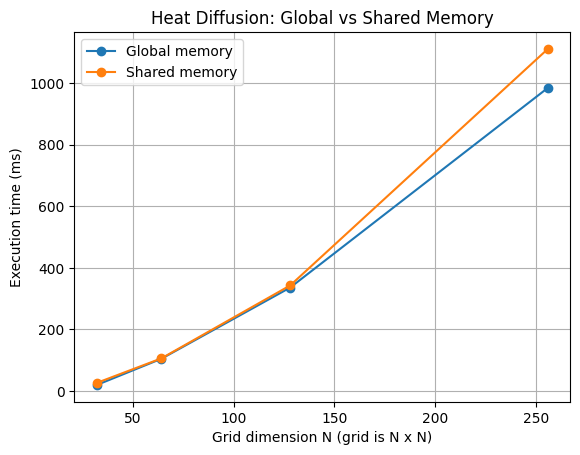

In [ ]:
import subprocess
import re
import pandas as pd
import matplotlib.pyplot as plt

grid_sizes = [32, 64, 128, 256]
repeats = 3
records = []

# One warm-up run per implementation and grid size.
for n in grid_sizes:
    for program in ["./heat_diffusion", "./heat_shared"]:
        subprocess.run(
            [program, str(n)],
            capture_output=True, text=True, check=True
        )

# Collect three measurements for each case.
for n in grid_sizes:
    for version, program in [
        ("Global memory", "./heat_diffusion"),
        ("Shared memory", "./heat_shared")
    ]:
        times = []

        for run in range(repeats):
            result = subprocess.run(
                [program, str(n)],
                capture_output=True, text=True, check=True
            )

            match = re.search(
                r"Execution time \(ms\):\s*([\d.]+)",
                result.stdout
            )

            if not match:
                raise RuntimeError(
                    f"Could not read execution time for {program}, N={n}"
                )

            times.append(float(match.group(1)))

        records.append({
            "Grid size": f"{n}x{n}",
            "N": n,
            "Version": version,
            "Median time (ms)": sorted(times)[len(times)//2],
            "All runs (ms)": ", ".join(f"{t:.2f}" for t in times)
        })

df = pd.DataFrame(records)

print("Benchmark results:")
display(df[["Grid size", "Version", "Median time (ms)", "All runs (ms)"]])

# Compare median times and calculate speedup.
wide = df.pivot(
    index="N", columns="Version", values="Median time (ms)"
)
wide["Speedup (global/shared)"] = (
    wide["Global memory"] / wide["Shared memory"]
)

print("\nSpeedup comparison:")
display(wide.round(3))

# Plot execution time.
for version in ["Global memory", "Shared memory"]:
    subset = df[df["Version"] == version]
    plt.plot(
        subset["N"], subset["Median time (ms)"],
        marker="o", label=version
    )

plt.xlabel("Grid dimension N (grid is N x N)")
plt.ylabel("Execution time (ms)")
plt.title("Heat Diffusion: Global vs Shared Memory")
plt.legend()
plt.grid(True)
plt.show()

2D Heat Diffusion Lab
An Interactive CUDA Programming Demonstration

Explore heat diffusion through an interactive temperature map, watch the numerical solution evolve over iterations, and compare the measured performance of global-memory and shared-memory CUDA implementations.
Interactive Visualization
Convergence Detection
CUDA Benchmarking

In [ ]:
import numpy as np

global_grid = np.loadtxt("cuda_grid.txt")
shared_grid = np.loadtxt("cuda_shared_grid.txt")

print("Global grid shape:", global_grid.shape)
print("Shared grid shape:", shared_grid.shape)

print("Maximum absolute difference:",
      np.max(np.abs(global_grid - shared_grid)))

print("Results match within 0.001:",
      np.allclose(global_grid, shared_grid, atol=1e-3))

Global grid shape: (256, 256)
Shared grid shape: (256, 256)
Maximum absolute difference: 0.0
Results match within 0.001: True


In [4]:
import numpy as np
import matplotlib.pyplot as plt

print("Python and NumPy are ready!")

Python and NumPy are ready!


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import ipywidgets as widgets

def simulate_heat(N=32, tolerance=1e-4, max_iterations=100000):
    grid = np.zeros((N, N), dtype=np.float32)
    grid[0, :] = 100.0

    for iteration in range(1, max_iterations + 1):
        new_grid = grid.copy()

        new_grid[1:-1, 1:-1] = (
            grid[:-2, 1:-1] +
            grid[2:, 1:-1] +
            grid[1:-1, :-2] +
            grid[1:-1, 2:]
        ) / 4.0

        change = np.max(np.abs(new_grid - grid))
        grid = new_grid

        if change < tolerance:
            return grid, iteration, float(change)

    return grid, max_iterations, float(change)

grid_size = widgets.Dropdown(
    options=[10, 32, 64, 128],
    value=32,
    description="Grid size:"
)

tolerance = widgets.Dropdown(
    options=[1e-3, 1e-4, 1e-5],
    value=1e-4,
    description="Tolerance:"
)

run_button = widgets.Button(
    description="Run heat simulation",
    button_style="success"
)

output = widgets.Output()

def run_simulation(_):
    with output:
        clear_output(wait=True)

        grid, iterations, max_change = simulate_heat(
            N=grid_size.value,
            tolerance=tolerance.value
        )

        plt.figure(figsize=(7, 5))
        plt.imshow(grid, cmap="inferno", origin="upper")
        plt.colorbar(label="Temperature (°C)")
        plt.title(f"2D Heat Diffusion — {grid_size.value} × {grid_size.value}")
        plt.xlabel("X coordinate")
        plt.ylabel("Y coordinate")
        plt.show()

        print(f"Grid size: {grid_size.value} × {grid_size.value}")
        print(f"Iterations: {iterations}")
        print(f"Maximum change: {max_change:.8g}")
        print(f"Tolerance: {tolerance.value}")
        print("Converged:", max_change < tolerance.value)
        print("Execution: Python CPU reference (not CUDA)")

run_button.on_click(run_simulation)

display(widgets.HBox([grid_size, tolerance]), run_button, output)

Button(button_style='success', description='Run heat simulation', style=ButtonStyle())

Output()

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Animation settings
N = 32
tolerance_anim = 1e-4
snapshot_interval = 25

# Initialize the same temperature grid
grid = np.zeros((N, N), dtype=np.float32)
grid[0, :] = 100.0

snapshots = [(0, grid.copy(), float("inf"))]
iteration = 0

# Run the heat simulation and save periodic snapshots
while True:
    new_grid = grid.copy()

    new_grid[1:-1, 1:-1] = (
        grid[:-2, 1:-1] +
        grid[2:, 1:-1] +
        grid[1:-1, :-2] +
        grid[1:-1, 2:]
    ) / 4.0

    max_change = float(np.max(np.abs(new_grid - grid)))
    grid = new_grid
    iteration += 1

    if iteration % snapshot_interval == 0:
        snapshots.append((iteration, grid.copy(), max_change))

    if max_change < tolerance_anim:
        snapshots.append((iteration, grid.copy(), max_change))
        break

print(f"Converged after {iteration} iterations.")
print(f"Saved {len(snapshots)} animation frames.")

# Animate the saved temperature grids
fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(
    snapshots[0][1],
    cmap="inferno",
    origin="upper",
    vmin=0,
    vmax=100,
    interpolation="nearest"
)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Temperature (°C)")

title = ax.set_title("2D Heat Diffusion — Iteration 0")
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")

def update(frame):
    step, temperature_grid, change = snapshots[frame]
    image.set_data(temperature_grid)
    title.set_text(
        f"Heat Diffusion — Iteration {step} | "
        f"Max change: {change:.3e}"
    )
    return image, title

anim = FuncAnimation(
    fig,
    update,
    frames=len(snapshots),
    interval=150,
    blit=False,
    init_func=lambda: update(0)
)
plt.close(fig)
display(HTML(anim.to_jshtml()))


Converged after 1490 iterations.
Saved 61 animation frames.


In [8]:

import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# Previously measured CUDA benchmark medians (milliseconds)
benchmark_data = pd.DataFrame({
    "Grid size": [32, 64, 128, 256],
    "Global memory (ms)": [19.8593, 104.7550, 336.0070, 984.3600],
    "Shared memory (ms)": [26.6397, 106.0160, 342.8780, 1110.8600]
})

benchmark_data["Speedup (global/shared)"] = (
    benchmark_data["Global memory (ms)"] /
    benchmark_data["Shared memory (ms)"]
)

grid_selector = widgets.Dropdown(
    options=[32, 64, 128, 256],
    value=256,
    description="Grid size:"
)

show_all_button = widgets.Button(
    description="Show all grid sizes",
    button_style="info"
)

benchmark_output = widgets.Output()

def show_benchmark(grid_size=None):
    with benchmark_output:
        clear_output(wait=True)

        if grid_size is None:
            results = benchmark_data
        else:
            results = benchmark_data[
                benchmark_data["Grid size"] == grid_size
            ]

        display(results.round(4))

        if grid_size is not None:
            row = results.iloc[0]
            faster = (
                "Global memory"
                if row["Global memory (ms)"] < row["Shared memory (ms)"]
                else "Shared memory"
            )

            print(f"\nGrid: {grid_size} × {grid_size}")
            print(f"Faster measured version: {faster}")
            print(
                "Global/shared ratio: "
                f"{row['Speedup (global/shared)']:.3f}×"
            )

        plt.figure(figsize=(8, 4.5))
        plt.plot(
            benchmark_data["Grid size"],
            benchmark_data["Global memory (ms)"],
            marker="o", label="Global memory"
        )
        plt.plot(
            benchmark_data["Grid size"],
            benchmark_data["Shared memory (ms)"],
            marker="o", label="Shared memory"
        )
        plt.xlabel("Grid dimension N (N × N)")
        plt.ylabel("Median execution time (ms)")
        plt.title("CUDA Heat Diffusion — Recorded Benchmark Results")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()

        print(
            "Source: Previously measured CUDA benchmark results; "
            "this panel does not run a new GPU benchmark."
        )

def on_grid_change(change):
    if change["name"] == "value":
        show_benchmark(change["new"])

grid_selector.observe(on_grid_change, names="value")
show_all_button.on_click(lambda _: show_benchmark())

display(grid_selector, show_all_button, benchmark_output)
show_benchmark(256)


Dropdown(description='Grid size:', index=3, options=(32, 64, 128, 256), value=256)

Button(button_style='info', description='Show all grid sizes', style=ButtonStyle())

Output()

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# Previously measured CUDA benchmark medians (milliseconds)
benchmarks = pd.DataFrame({
    "Grid size": [32, 64, 128, 256],
    "Global memory (ms)": [19.8593, 104.7550, 336.0070, 984.3600],
    "Shared memory (ms)": [26.6397, 106.0160, 342.8780, 1110.8600]
})
benchmarks["Global/shared ratio"] = (
    benchmarks["Global memory (ms)"] /
    benchmarks["Shared memory (ms)"]
)

def run_cpu_simulation(N, tolerance, max_iterations=100000):
    grid = np.zeros((N, N), dtype=np.float32)
    grid[0, :] = 100.0

    for iteration in range(1, max_iterations + 1):
        new_grid = grid.copy()
        new_grid[1:-1, 1:-1] = (
            grid[:-2, 1:-1] +
            grid[2:, 1:-1] +
            grid[1:-1, :-2] +
            grid[1:-1, 2:]
        ) / 4.0

        change = float(np.max(np.abs(new_grid - grid)))
        grid = new_grid

        if change < tolerance:
            return grid, iteration, change, True

    return grid, max_iterations, change, False

# Dashboard controls
grid_control = widgets.Dropdown(
    options=[32, 64, 128],
    value=32,
    description="Grid size:"
)

tol_control = widgets.Dropdown(
    options=[
        ("1e-3", 1e-3),
        ("1e-4", 1e-4),
        ("1e-5", 1e-5)
    ],
    value=1e-4,
    description="Tolerance:"
)

run_control = widgets.Button(
    description="Run dashboard",
    button_style="success",
    icon="play"
)

dashboard_output = widgets.Output()

def render_dashboard(_):
    with dashboard_output:
        clear_output(wait=True)

        N = grid_control.value
        tol = tol_control.value

        grid, iterations, change, converged = run_cpu_simulation(N, tol)

        status = "CONVERGED" if converged else "MAXIMUM ITERATIONS REACHED"
        status_color = "#16803c" if converged else "#b45309"

        display(HTML(f"""
        <div style="border:1px solid #ccc;border-radius:12px;
                    padding:16px;margin:8px 0">
          <h2 style="margin-top:0">Simulation Summary</h2>
          <div style="display:flex;flex-wrap:wrap;gap:12px">
            <div style="flex:1;min-width:130px;padding:12px;
                        background:#e8f2ff;border-radius:8px">
              <b>Grid</b><h2>{N} × {N}</h2>
            </div>
            <div style="flex:1;min-width:130px;padding:12px;
                        background:#e8f2ff;border-radius:8px">
              <b>Iterations</b><h2>{iterations:,}</h2>
            </div>
            <div style="flex:1;min-width:130px;padding:12px;
                        background:#e8f2ff;border-radius:8px">
              <b>Max change</b><h2>{change:.3e}</h2>
            </div>
          </div>
          <p><b>Status:</b>
             <span style="color:{status_color}">{status}</span></p>
          <p><b>Tolerance:</b> {tol:g}</p>
          <p><b>Simulation:</b> Python CPU reference, not CUDA</p>
        </div>
        """))

        # Final temperature visualization
        fig, ax = plt.subplots(figsize=(7, 5))
        im = ax.imshow(
            grid, cmap="inferno", origin="upper",
            vmin=0, vmax=100, interpolation="nearest"
        )
        fig.colorbar(im, ax=ax, label="Temperature (°C)")
        ax.set_title(f"Final Temperature Distribution — {N} × {N}")
        ax.set_xlabel("X coordinate")
        ax.set_ylabel("Y coordinate")
        plt.show()

        # Recorded CUDA benchmark comparison
        selected = benchmarks[benchmarks["Grid size"] == N]
        if selected.empty:
            selected = benchmarks[benchmarks["Grid size"] == 32]

        print("RECORDED CUDA PERFORMANCE RESULTS")
        display(selected.round(4).reset_index(drop=True))

        print(
            "Note: These are previously measured CUDA timings. "
            "This dashboard does not execute a new GPU benchmark."
        )

        print("\nALL RECORDED BENCHMARKS")
        display(benchmarks.round(4).reset_index(drop=True))

run_control.on_click(render_dashboard)

display(HTML("""
<h1>2D Heat Diffusion Lab</h1>
<p>Explore numerical heat diffusion, convergence, and recorded CUDA
performance results in one place.</p>
<p><b>Visualization:</b> CPU reference simulation.
<b>Performance:</b> previously measured CUDA results.</p>
"""))
display(widgets.HBox([grid_control, tol_control]), run_control)
display(dashboard_output)

# Automatically display the initial dashboard
render_dashboard(None)


Button(button_style='success', description='Run dashboard', icon='play', style=ButtonStyle())

Output()

## Performance Analysis: Global Memory vs Shared Memory

Both CUDA implementations were evaluated on a Tesla T4 GPU using grid sizes of 32 × 32, 64 × 64, 128 × 128, and 256 × 256. Three measurements were collected for each configuration, and the median execution time was used for comparison.

The global-memory implementation achieved lower execution times at all four grid sizes. The shared-memory implementation showed similar performance at 64 × 64 and 128 × 128, but was slower at 32 × 32 and 256 × 256.

The results suggest that shared-memory tiling did not provide an end-to-end performance benefit for the tested configurations. Tile-loading overhead, synchronization, and repeated convergence checks may contribute to this outcome.

Both implementations reached the specified convergence tolerance. Further optimization could investigate reducing host-device synchronization and measuring kernel execution time separately from convergence handling.

**Conclusion:** Shared-memory tiling is not automatically faster than global-memory access. Its effectiveness depends on the workload, memory-access patterns, and synchronization overhead.

## Validation and Experimental Results

### Correctness
- The simulation uses the five-point stencil formula to update interior temperature cells.
- Boundary temperatures remain fixed during the simulation.
- Convergence is determined by comparing the maximum temperature change with the specified tolerance.
- The Python CPU reference and CUDA implementations were compared during validation.

### Performance Comparison
- Four grid sizes were benchmarked: 32 × 32, 64 × 64, 128 × 128, and 256 × 256.
- The global-memory implementation achieved lower measured execution times for all four tested configurations.
- Shared-memory tiling did not provide an end-to-end speedup in these experiments.

### Limitations
- The interactive heatmap and animation currently run on the CPU.
- The performance panel displays previously recorded CUDA measurements; it does not execute new GPU benchmarks.
- Further optimization could investigate memory access patterns, synchronization overhead, and convergence-check costs.

### Conclusion
This project demonstrates iterative 2D heat diffusion, numerical convergence detection, CUDA implementation strategies, correctness validation, and empirical performance comparison. The results illustrate that shared-memory optimization does not guarantee better performance for every workload.
